<a href="https://colab.research.google.com/github/yeugeneu/IAT360-CV-13-Cloud-Type-Classifier/blob/Baseline-Training/Cloud_type_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Preprocessing
We have to convert the dataset into that acceptable by YOLO.
- Heirarchy of folders should be the one accepted by YOLO
- Labels format should be object detection for YOLOv8
```
class x_center y_center width height
```

- Labels files should be .txt files with an object in the image per row

1. Make sure you download and extract the dataset [CloudDataset](https://app.roboflow.com/eugene-yu/cloud-qthye-mirzy/1) forked from [Roboflow Cloud Computer Vision Model dataset](https://universe.roboflow.com/ip2-kbjz5/cloud-qthye/browse?queryText=&pageSize=100&startingIndex=0&browseQuery=true)


2. Rename the folder to 'CloudDataset'

3. Below steps will guide you through converting the original dataset to the folder hierarchy we wish to use


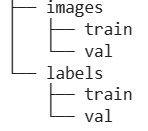

## Import required libraries

In [ ]:
import glob
import os
import random
import shutil
from PIL import Image
import cv2
import matplotlib.pyplot as plt
import pandas as pd

## Re-organize source Dataset images/labels

Load all images and labels located inside the "CloudDataset" folder

In [ ]:
# Set train, validate, and test dataset paths
train_dir_img = 'CloudDataset/train/images'
train_dir_lbl = 'CloudDataset/train/labels'

val_dir_img = 'CloudDataset/valid/images'
val_dir_lbl = 'CloudDataset/valid/labels'

In [ ]:
import os

# Define source directory paths directly
train_dir_img = 'CloudDataset/train/images'
train_dir_lbl = 'CloudDataset/train/labels'

val_dir_img = 'CloudDataset/valid/images'
val_dir_lbl = 'CloudDataset/valid/labels'

test_dir_img = 'CloudDataset/test/images'
test_dir_lbl = 'CloudDataset/test/labels'

# Define directories to clean
dirs_to_clean = [
    (train_dir_img, train_dir_lbl),
    (val_dir_img, val_dir_lbl)
]

seen_bases = set()

for img_dir, lbl_dir in dirs_to_clean:
    if not os.path.exists(img_dir):
        print(f"Directory does not exist, skipping: {img_dir}")
        continue

    files = sorted(os.listdir(img_dir))

    removed_count = 0
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            # Roboflow export formats usually contain '.rf.' before the unique hash
            # e.g., 'Ac-N001_jpg.rf.8c98886d88bb955b60652b2a5f2f42a6.jpg' -> base 'Ac-N001_jpg'
            if '.rf.' in file:
                base_name = file.split('.rf.')[0]
            else:
                base_name = os.path.splitext(file)[0]

            img_path = os.path.join(img_dir, file)

            # Match corresponding label txt file
            label_file = os.path.splitext(file)[0] + '.txt'
            lbl_path = os.path.join(lbl_dir, label_file)

            if base_name in seen_bases:
                # Duplicate found, remove both image and label
                if os.path.exists(img_path):
                    os.remove(img_path)
                if os.path.exists(lbl_path):
                    os.remove(lbl_path)
                removed_count += 1
            else:
                # First instance, keep it
                seen_bases.add(base_name)

    print(f"Cleaned {img_dir}: Kept {len(seen_bases)} unique images, removed {removed_count} augmented instances.")

Cleaned CloudDataset/train/images: Kept 2310 unique images, removed 1119 augmented instances.
Cleaned CloudDataset/valid/images: Kept 2521 unique images, removed 646 augmented instances.


Create new root folder called "All_data", with 2 child folders "images" and "labels"

In [ ]:
os.makedirs('All_data/images')
os.makedirs('All_data/labels')

Copy the label txt files and image jpg files to the new folders created

In [ ]:
#set the paths to labels and images directory for All data
label_dir= "All_data/labels"
image_dir= "All_data/images"

In [ ]:
# Source directories mapped to their target categories
image_sources = [train_dir_img, val_dir_img]
label_sources = [train_dir_lbl, val_dir_lbl]

# Copy and process all images to image_dir
for src_dir in image_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                try:
                    img_path = os.path.join(src_dir, file)
                    image = Image.open(img_path)
                    image = image.convert("RGB")
                    base, ext = os.path.splitext(file)
                    # Replace '.' with '-' in the filename base
                    safe_base = base.replace(".", "-")
                    new_filename = safe_base + ".jpg"
                    image.save(os.path.join(image_dir, new_filename), "JPEG")
                except Exception as e:
                    print(f"Error processing image {file}: {e}")

# Copy all label files to label_dir
for src_dir in label_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith(".txt"):
                base, ext = os.path.splitext(file)
                # Replace '.' with '-' in the filename base
                safe_base = base.replace(".", "-")
                new_filename = safe_base + ext
                shutil.copy(os.path.join(src_dir, file), os.path.join(label_dir, new_filename))

Take a look at the first 4 images in the "Final_data/images" folder to make sure the images are moved correctly

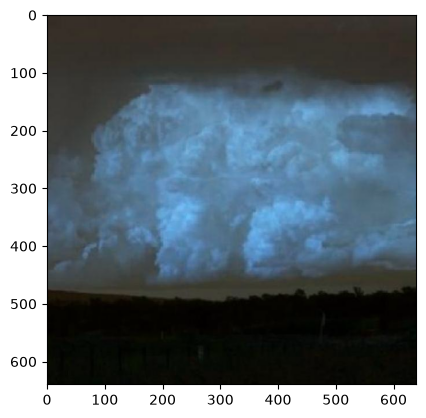

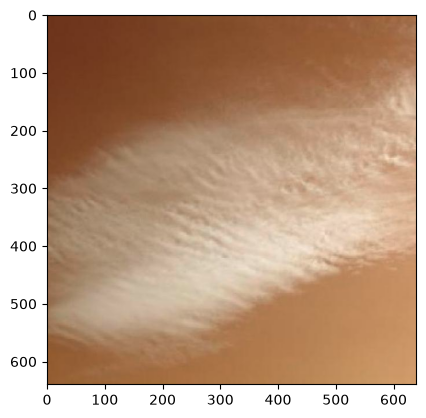

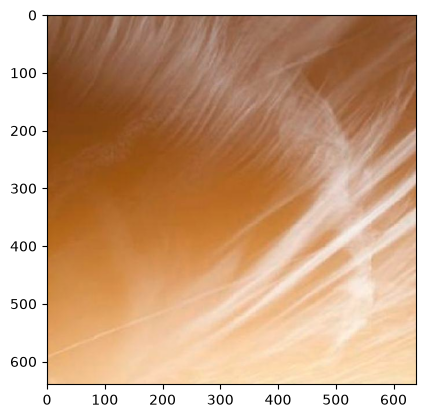

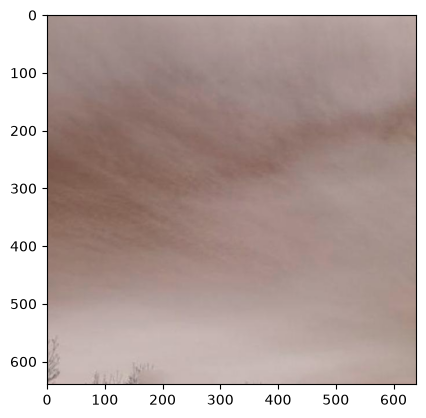

In [ ]:
#visualize first four sample images from train data
for idx, image in enumerate(os.listdir(os.path.join(image_dir))):
    img = cv2.imread(os.path.join(image_dir, image), 1)
    plt.imshow(img)
    plt.show()

    if idx == 3:
        break

Check the Data balance

class_name
Stratocumulus    344
Cirrostratus     288
Nimbostratus     274
Cirrocumulus     260
Cumulonimbus     235
Altocumulus      219
Contrails        205
Stratus          204
Altostratus      188
Cumulus          178
Cirrus           140
Name: count, dtype: int64


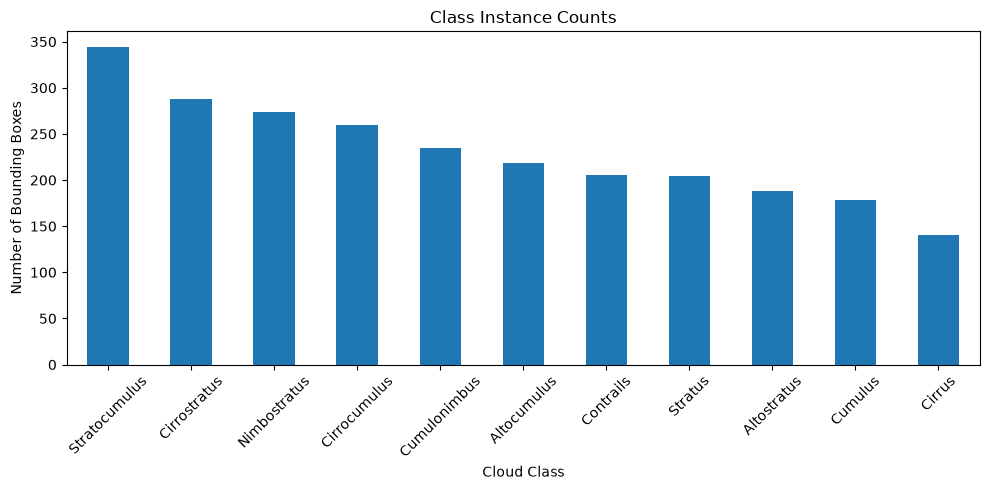

In [ ]:
# 1. Define your class mapping dictionary
class_map = {
    0: "Altocumulus",
    1: "Altostratus",
    2: "Cirrocumulus",
    3: "Cirrostratus",
    4: "Cirrus",
    5: "Contrails",
    6: "Cumulonimbus",
    7: "Cumulus",
    8: "Nimbostratus",
    9: "Stratocumulus",
    10: "Stratus"
}

# 2. Gather label annotation files
labels_dir = "All_data/labels"
annotation_files = glob.glob(os.path.join(labels_dir, "*.txt"))

records = []
for file in annotation_files:
    with open(file, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                records.append(int(parts[0]))

# Create DataFrame
df = pd.DataFrame(records, columns=['class_id'])

# Map class IDs to names
df['class_name'] = df['class_id'].map(class_map)

# Value counts table
print(df['class_name'].value_counts())

# Plot distribution
df['class_name'].value_counts().plot(kind='bar', figsize=(10, 5), title="Class Instance Counts")
plt.xlabel("Cloud Class")
plt.ylabel("Number of Bounding Boxes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Split the source data
Split into 80-20 train-validation sets and re-organize the data into correct sub-folders

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Load the sorted lists of all images and matching labels
# Sorting ensures that images and labels pair up correctly (e.g., image[i] matches label[i])
images_dir = "All_data/images"
labels_dir = "All_data/labels"

# Get all file names and sort them alphabetically
image_files = sorted(os.listdir(images_dir))
label_files = sorted(os.listdir(labels_dir))

# Double check we are matching base names (e.g., image_01.jpg maps to image_01.txt)
# We'll filter to make sure we only split perfectly matching image-label pairs
valid_images = []
valid_labels = []

for img in image_files:
    base_name = os.path.splitext(img)[0]
    label_name = f"{base_name}.txt"
    if label_name in label_files:
        valid_images.append(os.path.join(images_dir, img))
        valid_labels.append(os.path.join(labels_dir, label_name))

# 2. Split into 80% train+validation and 20% test set
X_train, X_validation, y_train, y_validation = train_test_split(
    valid_images,
    valid_labels,
    test_size=0.20,
    random_state=42
)

print(f"Split completed:")
print(f"  - Train set size: {len(X_train)} pairs")
print(f"  - Validation set size: {len(X_validation)} pairs")


Split completed:
  - Train set size: 2016 pairs
  - Validation set size: 505 pairs


In [ ]:
# Define the target subdirectories
splits = ['train', 'val']
for split in splits:
    os.makedirs(os.path.join("All_data/images", split), exist_ok=True)
    os.makedirs(os.path.join("All_data/labels", split), exist_ok=True)

# Helper function to move a list of files to their respective folder
def move_files(file_paths, destination_folder):
    for path in file_paths:
        if os.path.exists(path):
            filename = os.path.basename(path)
            shutil.move(path, os.path.join(destination_folder, filename))

# Move image sets
move_files(X_train, "All_data/images/train")
move_files(X_validation, "All_data/images/val")

# Move label sets
move_files(y_train, "All_data/labels/train")
move_files(y_validation, "All_data/labels/val")

# Verify counts in new structured folders
print("\nPhysical Split Verification:")
for split in splits:
    img_count = len(os.listdir(os.path.join("All_data/images", split)))
    lbl_count = len(os.listdir(os.path.join("All_data/labels", split)))
    print(f"  - {split.capitalize()} Set: {img_count} images | {lbl_count} labels")



Physical Split Verification:
  - Train Set: 2016 images | 2016 labels
  - Val Set: 505 images | 505 labels


## Organize group member images and Move them into test folder as test set

Download the images collected from all 4 group members ([FirstName]_Cloud_Data_Labeled) located in this link https://1sfu-my.sharepoint.com/:f:/r/personal/yya6_sfu_ca/Documents/CV%20Project%20Group%2013?d=w11d6cbb929af48b29ee060bcf9c1bf78&csf=1&web=1&e=WJnLSs


In [ ]:
# creates Members_Dataset and moves every folder ending in _CloudData_Labeled
import os, shutil

os.makedirs("Members_Dataset", exist_ok=True)

for name in os.listdir("."):
    if name.endswith("_CloudData_Labeled") and os.path.isdir(name):
        shutil.move(name, os.path.join("Members_Dataset", name))
        print("moved", name)

# show what's inside so you can check the structure
for name in os.listdir("Members_Dataset"):
    print(name, "->", os.listdir(os.path.join("Members_Dataset", name)))

Dalena_CloudData_Labeled -> ['classes.txt', '.DS_Store', 'images', 'labels', 'notes.json']
Marielle_CloudData_Labeled -> ['classes.txt', '.DS_Store', 'images', 'labels', 'notes.json']
Eugene_CloudData_Labeled -> ['classes.txt', '.DS_Store', 'images', 'labels', 'notes.json']
Martina_CloudData_Labeled -> ['classes.txt', '.DS_Store', 'images', 'labels', 'notes.json']


In [ ]:
# Set all paths to the dataset
eugene_dir_img = 'Members_Dataset/Eugene_CloudData_Labeled/images'
eugene_dir_lbl = 'Members_Dataset/Eugene_CloudData_Labeled/labels'

dalena_dir_img = 'Members_Dataset/Dalena_CloudData_Labeled/images'
dalena_dir_lbl = 'Members_Dataset/Dalena_CloudData_Labeled/labels'

martina_dir_img = 'Members_Dataset/Martina_CloudData_Labeled/images'
martina_dir_lbl = 'Members_Dataset/Martina_CloudData_Labeled/labels'

marielle_dir_img = 'Members_Dataset/Marielle_CloudData_Labeled/images'
marielle_dir_lbl = 'Members_Dataset/Marielle_CloudData_Labeled/labels'

Copy the label txt files and image jpg files to the new folders created

In [ ]:
#set the paths to labels and images directory for test data
test_label_dir= "All_data/labels/test"
test_image_dir= "All_data/images/test"

os.makedirs(os.path.join("All_data/labels/test"), exist_ok=True)
os.makedirs(os.path.join("All_data/images/test"), exist_ok=True)

Every image from every member gets converted to RGB .jpg and saved into All_data/images/test. Every label .txt from every member gets copied into All_data/labels/test

In [ ]:
# Source directories mapped to their target categories
image_sources = [eugene_dir_img, dalena_dir_img, martina_dir_img, marielle_dir_img]
label_sources = [eugene_dir_lbl, dalena_dir_lbl, martina_dir_lbl, marielle_dir_lbl]

# Copy and process all images to test_image_dir
for src_dir in image_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                try:
                    img_path = os.path.join(src_dir, file)
                    image = Image.open(img_path)
                    image = image.convert("RGB")
                    new_filename = os.path.splitext(file)[0] + ".jpg"
                    image.save(os.path.join(test_image_dir, new_filename), "JPEG")
                except Exception as e:
                    print(f"Error processing image {file}: {e}")

# Copy all label files to test_label_dir
for src_dir in label_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith(".txt"):
                shutil.copy(os.path.join(src_dir, file), os.path.join(test_label_dir, file))

## Check for missing files

Each set should contain the same amount of images and labels

In [ ]:
train_img = "All_data/images/train"
train_lbl = "All_data/labels/train"
val_img = "All_data/images/val"
val_lbl = "All_data/labels/val"
test_img = "All_data/images/test"
test_lbl = "All_data/labels/test"

# Group the folder pairs together for verification
pairs = [
    ("Train Set", train_img, train_lbl),
    ("Validation Set", val_img, val_lbl),
    ("Test Set", test_img, test_lbl)
]

for name, img_folder, lbl_folder in pairs:
    num_images = len([f for f in os.listdir(img_folder) if os.path.isfile(os.path.join(img_folder, f))])
    num_labels = len([f for f in os.listdir(lbl_folder) if os.path.isfile(os.path.join(lbl_folder, f))])
    print(f"{name}: {num_images} images | {num_labels} labels")
    assert num_images == num_labels, f"Mismatch in {name}! Images: {num_images}, Labels: {num_labels}"

Train Set: 2016 images | 2016 labels
Validation Set: 505 images | 505 labels
Test Set: 120 images | 120 labels


Randomly pick an image and a label from each set to check if annotation can be populated

Visualizing from train set: Ac-N130_jpg-rf-0210ab888ac4303e89495a3d99262bde.jpg


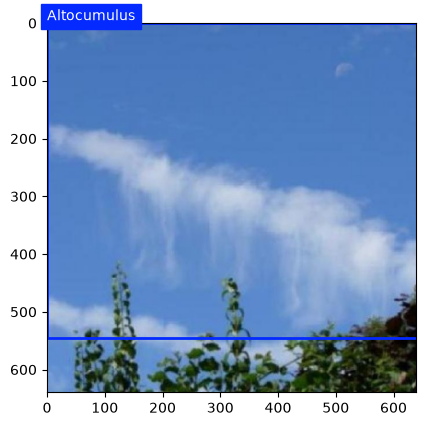

Visualizing from val set: Ct-N196_jpg-rf-1e61c589c9ed603081a9f328540caee7.jpg


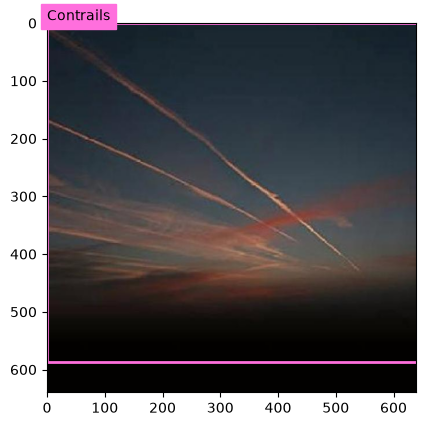

Visualizing from test set: e9dd9ad0-own_marielle_02.jpg


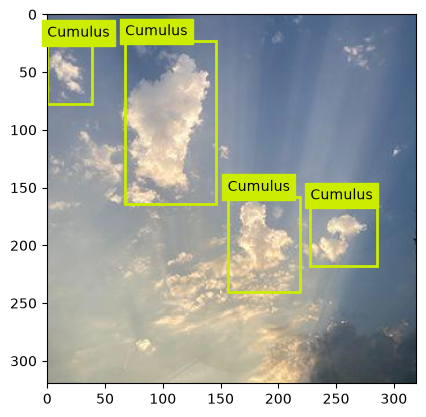

In [ ]:
from ultralytics.data.utils import visualize_image_annotations
# define the class map
class_map = {
    0: "Altocumulus",
    1: "Altostratus",
    2: "Cirrocumulus",
    3: "Cirrostratus",
    4: "Cirrus",
    5: "Contrails",
    6: "Cumulonimbus",
    7: "Cumulus",
    8: "Nimbostratus",
    9: "Stratocumulus",
    10: "Stratus"
}

# Splits to choose from
splits = ["train", "val", "test"]

for split in splits:
    img_dir = f"All_data/images/{split}"
    lbl_dir = f"All_data/labels/{split}"

    if os.path.exists(img_dir) and os.path.exists(lbl_dir):
        # Get a list of all image files in this split
        image_files = [f for f in os.listdir(img_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))]

        if image_files:
            # Pick 1 random image from this split
            random_image = random.choice(image_files)

            # Construct matching image and label paths
            base_name = os.path.splitext(random_image)[0]
            random_image_path = os.path.join(img_dir, random_image)
            random_label_path = os.path.join(lbl_dir, f"{base_name}.txt")

            # Visualize
            print(f"Visualizing from {split} set: {random_image}")
            visualize_image_annotations(
                random_image_path,
                random_label_path,
                class_map,
            )
        else:
            print(f"No images found in {img_dir}")
    else:
        print(f"Directory does not exist for split: {split}")

# Model Training

In [ ]:
%pip install ultralytics
import ultralytics

ultralytics.checks()

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


In [ ]:
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/IAT 360/All_data.zip"
extract_path = "/content/drive/MyDrive/IAT 360/"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction complete!")

Extraction complete!


In [ ]:
%cd "/content/drive/MyDrive/IAT 360"
%pwd
%ls

/content/drive/MyDrive/IAT 360
All_data/  All_data.zip  config.yaml  __MACOSX/  yolov8s.pt


In [ ]:
%%writefile config.yaml
path: All_data
train: images/train
val: images/val
test: images/test

# Classes
nc: 11 # replace based on your dataset's number of classes

# Class names
names:
    0: Altocumulus
    1: Altostratus
    2: Cirrocumulus
    3: Cirrostratus
    4: Cirrus
    5: Contrails
    6: Cumulonimbus
    7: Cumulus
    8: Nimbostratus
    9: Stratocumulus
    10: Stratus


Overwriting config.yaml


In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8s.pt')

In [ ]:
# Train using config.yaml and store results inside your Google Drive directory
model.train(
    data="config.yaml",
    epochs=50,                                                    # 50 epochs is a good baseline length
    patience=10,                                                  # Increased from 5 to 10 to avoid premature early stopping
    batch=16,                                                     # Standard batch size for 16GB GPU VRAM
    device=0,                                                     # Force training on the GPU (Tesla T4)
    project="/content/drive/MyDrive/IAT 360/runs",                 # Keep runs organized inside your Drive
    name="cloud_baseline_result_yolov8s"                         # Specific subfolder for this run
)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=config.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=cloud_baseline_result_yolov8s, nbs=64, nms=None, opset=None, optimize=False, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b4074c66430>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.

In [ ]:
!find /root /content -name "*.pt"

/content/drive/MyDrive/IAT 360/yolov8s.pt
/content/drive/MyDrive/IAT 360/runs/cloud_baseline_result_yolov8s/weights/last.pt
/content/drive/MyDrive/IAT 360/runs/cloud_baseline_result_yolov8s/weights/best.pt
/content/drive/MyDrive/custom_folder/train/weights/last.pt
/content/drive/MyDrive/custom_folder/train/weights/best.pt
/content/drive/MyDrive/best.pt


## Evaluation metrics


In [ ]:
best = YOLO(model.trainer.best)
metrics = best.val(data="config.yaml")

print("mAP50-95:", metrics.box.map)
print("mAP50:", metrics.box.map50)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

for name, m in zip(best.names.values(), metrics.box.maps):
    print(name, round(m, 3))

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 24.7±6.1 MB/s, size: 23.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/IAT 360/All_data/labels/val.cache... 505 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 505/505 176.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 3.0it/s 10.7s
                   all        505        507      0.439      0.607      0.536      0.468
           Altocumulus         40         40      0.352        0.4       0.38      0.349
           Altostratus         32         32      0.427      0.562       0.53      0.451
          Cirrocumulus         49         49      

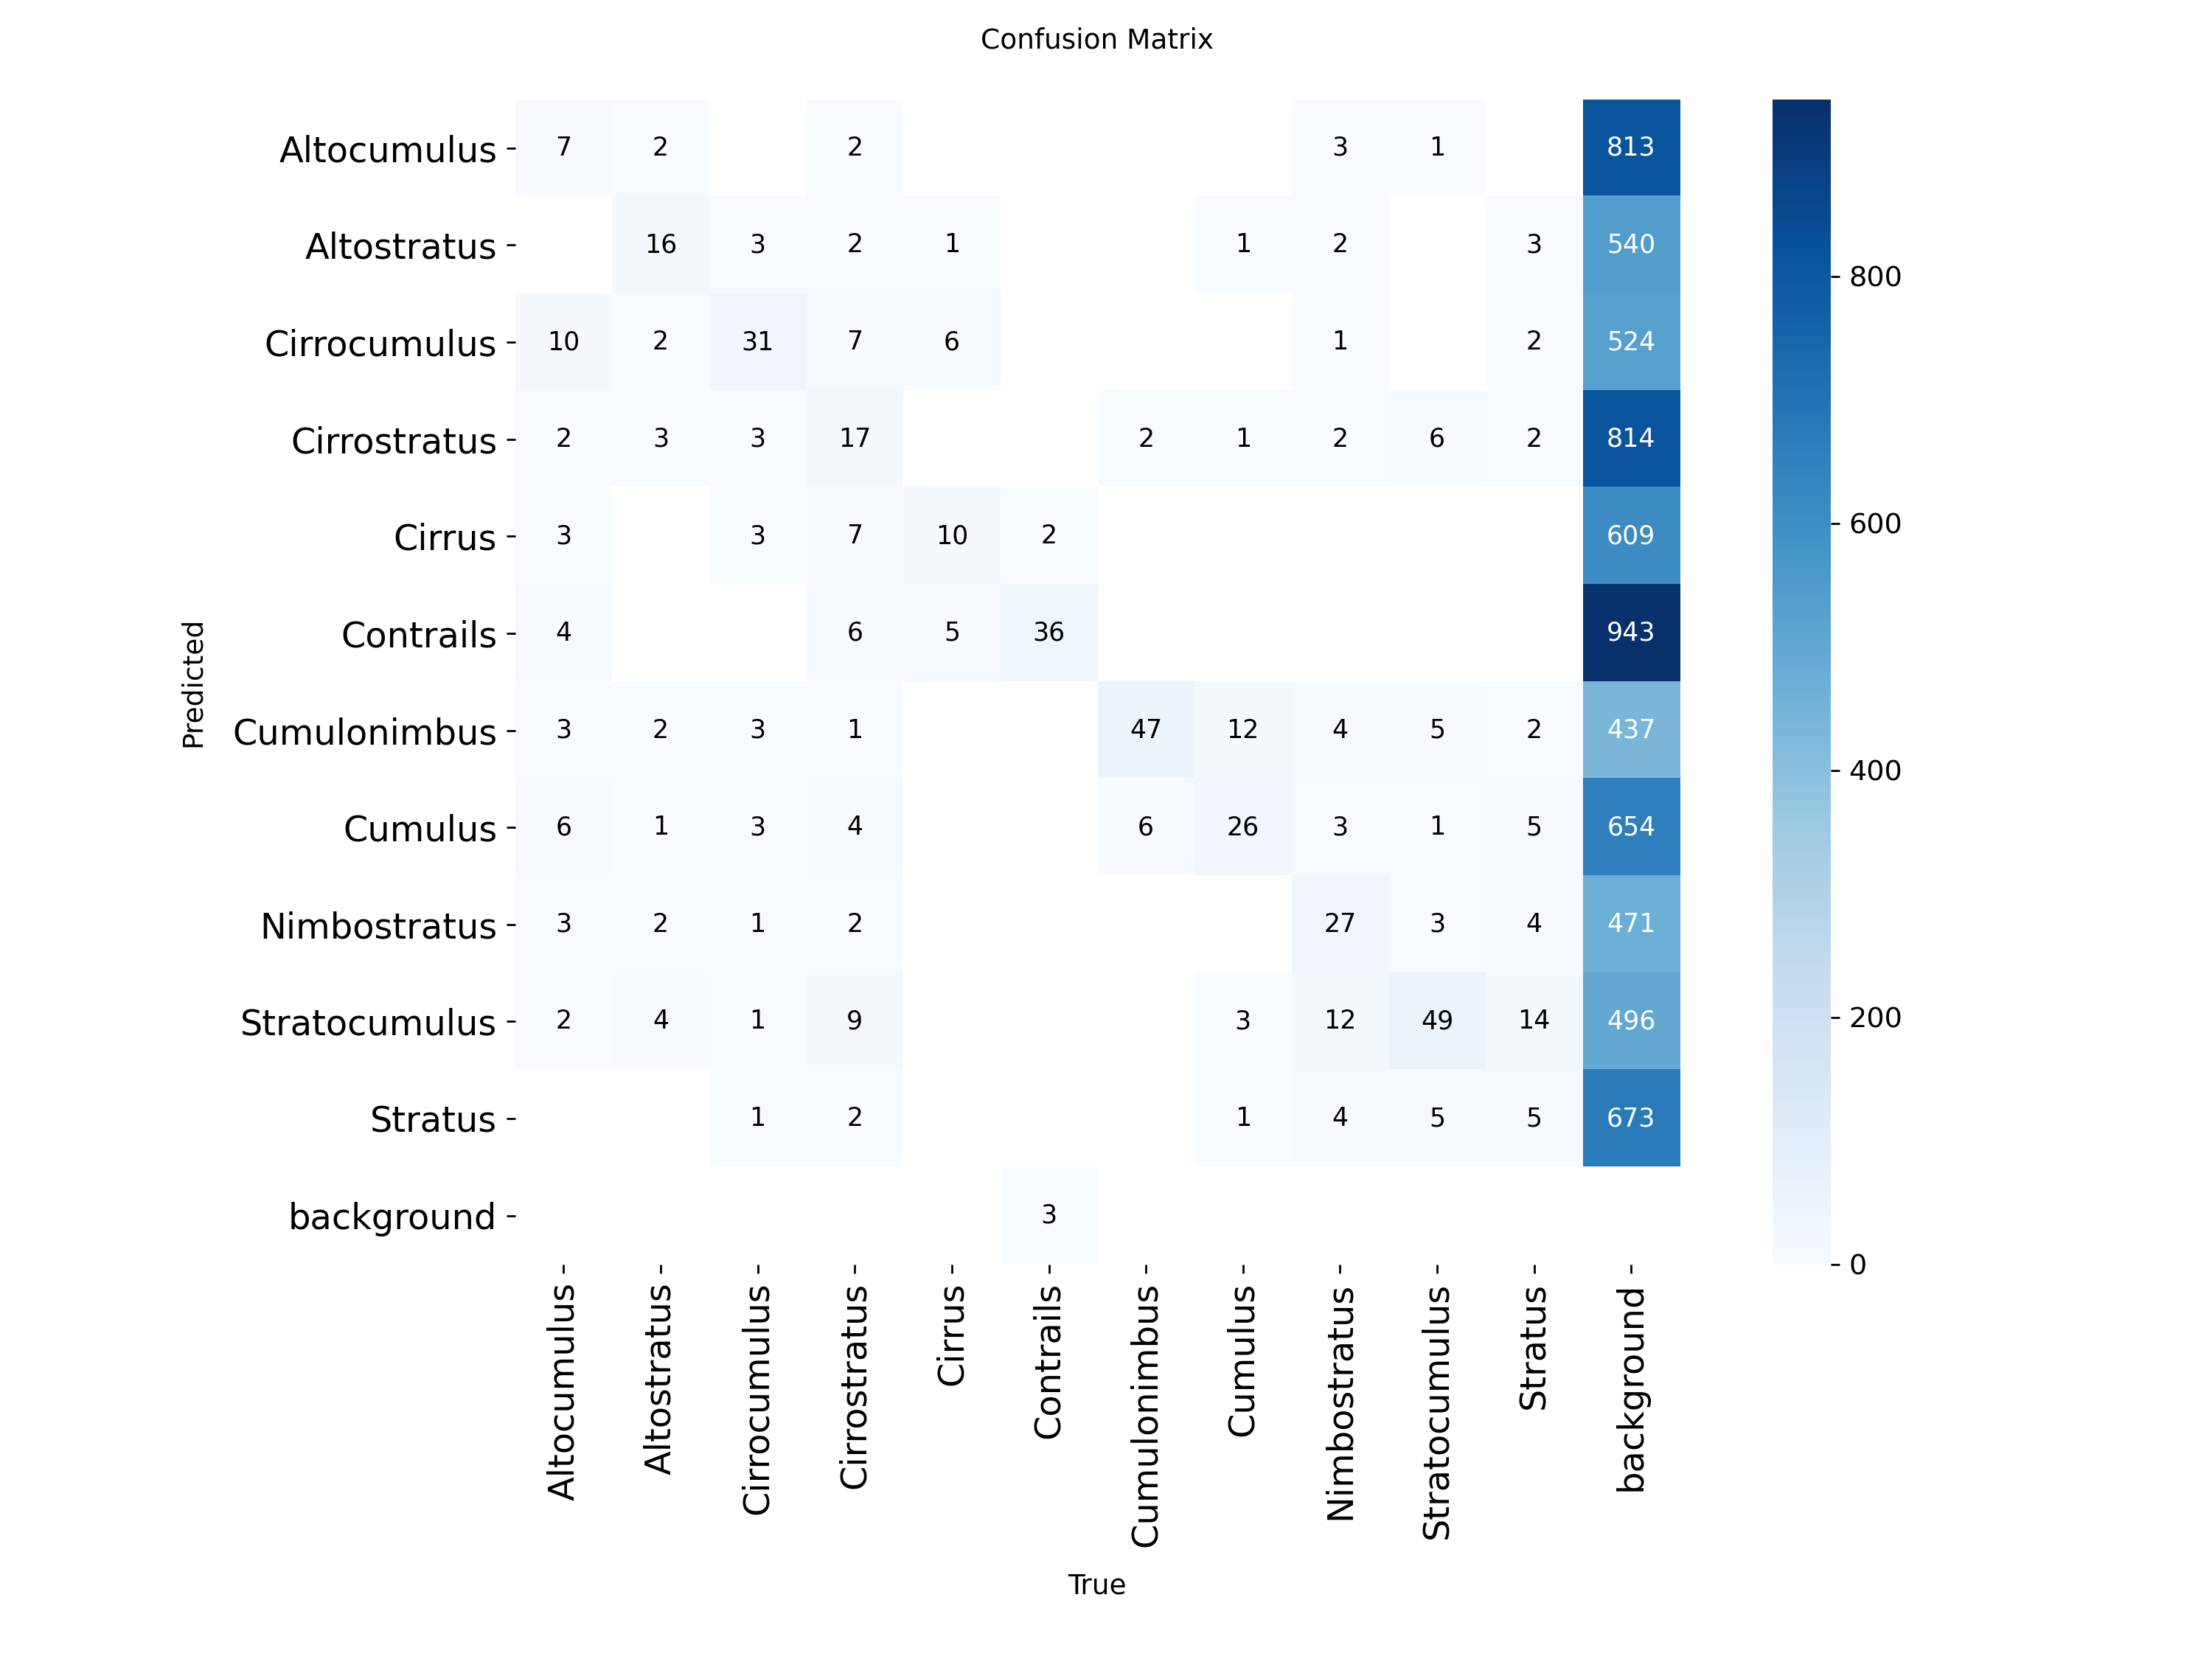

In [ ]:
%matplotlib inline
from PIL import Image

Image.open('runs/detect/val/confusion_matrix.png')

# Model Evaluation